# Chapter 15 — Statistical Modeling with Statsmodels

Statsmodels provides interpretable statistical models with coefficient estimates, uncertainty measures, diagnostics, and formal inference. Learn linear regression, categorical predictors, residual analysis, and time-series foundations.

## Prerequisites
Pandas, NumPy, descriptive statistics, and basic probability; SciPy statistics is recommended.

## Learning goals
- Fit and interpret ordinary least squares regression.
- Use formulas and categorical variables safely.
- Interpret coefficients, confidence intervals, p-values, and model fit.
- Evaluate residual assumptions and recognize model limitations.
- Understand the introductory workflow for time-series analysis.

**Study sequence:** use the theory notebook first, then tutorial, then lab. The examples use the bundled synthetic data unless otherwise noted.

In [1]:
from pathlib import Path
ROOT=Path.cwd()
if not (ROOT/"data").exists() and (ROOT.parent/"data").exists(): ROOT=ROOT.parent
DATA=ROOT/"data"
print("Data directory:", DATA.resolve())

Data directory: /mnt/data/python_data_analysis_book/data


## Chapter map

1. Model specification and design matrices
2. Fit and inspect an OLS model
3. Inference and model fit
4. Assumptions and diagnostics
5. Prediction and leakage
6. Time-series entry points

### Model specification and design matrices
`statsmodels.api.OLS(endog, exog, missing="none")` fits a linear model; add an intercept explicitly with `sm.add_constant(X)`. Formula API `statsmodels.formula.api.ols("y ~ x1 + C(group)", data=df)` creates design matrices and handles categorical terms via `C()`. Formula operators include `+`, `:`, `*` (main effects plus interaction), and `-1` (remove intercept).

#### Demonstration 1 — Fit an interpretable regression

Run the code and inspect both the output and the assumptions behind it.

In [2]:
from pathlib import Path
ROOT=Path.cwd()
if not (ROOT/"data").exists() and (ROOT.parent/"data").exists(): ROOT=ROOT.parent
DATA=ROOT/"data"
print("Data directory:", DATA.resolve())
import pandas as pd, statsmodels.formula.api as smf
sales=pd.read_csv(DATA/"sales.csv")
model=smf.ols("revenue ~ units + discount + C(region)",data=sales).fit()
print(model.summary())

Data directory: /mnt/data/python_data_analysis_book/data
                            OLS Regression Results                            
Dep. Variable:                revenue   R-squared:                       0.177
Model:                            OLS   Adj. R-squared:                  0.159
Method:                 Least Squares   F-statistic:                     10.04
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           1.02e-08
Time:                        18:19:25   Log-Likelihood:                -3331.4
No. Observations:                 240   AIC:                             6675.
Df Residuals:                     234   BIC:                             6696.
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------

### Fit and inspect an OLS model
`model.fit(cov_type="nonrobust")` estimates coefficients; common robust covariance options include `HC0`–`HC3`, which alter standard errors and inference, not fitted coefficients. `summary()` provides coefficient table, confidence intervals, R-squared, F-statistic, and diagnostics. A coefficient is conditional on the other included predictors and model specification.

#### Demonstration 2 — Extract coefficients and confidence intervals

Run the code and inspect both the output and the assumptions behind it.

In [3]:
print(model.params); display(model.conf_int().rename(columns={0:"lower",1:"upper"})); print("R-squared:",model.rsquared,"Adjusted:",model.rsquared_adj)

Intercept            -119043.717639
C(region)[T.North]     35363.489664
C(region)[T.South]     31696.459377
C(region)[T.West]      55522.071439
units                  24722.909810
discount              231296.699960
dtype: float64
                            lower          upper
Intercept          -223719.812483  -14367.622795
C(region)[T.North]  -60845.847045  131572.826373
C(region)[T.South]  -62259.704724  125652.623479
C(region)[T.West]   -35333.622664  146377.765541
units                17719.963874   31725.855746
discount           -413631.311595  876224.711516
R-squared: 0.17657955370005995 Adjusted: 0.1589850997192921


### Inference and model fit
`params`, `bse`, `tvalues`, `pvalues`, `conf_int()`, `rsquared`, `rsquared_adj`, `fittedvalues`, and `resid` expose key results. R-squared is the fraction of outcome variation explained in-sample under the model definition; it does not establish causation, correct specification, or out-of-sample performance.

#### Demonstration 3 — Use robust standard errors

Run the code and inspect both the output and the assumptions behind it.

In [4]:
robust=model.get_robustcov_results(cov_type="HC3")
print(robust.summary())
print("Note: robust covariance changes uncertainty estimates, not the OLS fitted values.")

                            OLS Regression Results                            
Dep. Variable:                revenue   R-squared:                       0.177
Model:                            OLS   Adj. R-squared:                  0.159
Method:                 Least Squares   F-statistic:                     7.995
Date:                Wed, 04 Nov 2026   Prob (F-statistic):           5.62e-07
Time:                        18:19:25   Log-Likelihood:                -3331.4
No. Observations:                 240   AIC:                             6675.
Df Residuals:                     234   BIC:                             6696.
Df Model:                           5                                         
Covariance Type:                  HC3                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept           -1.19e+05   4.53

### Assumptions and diagnostics
Classical OLS inference relies on a suitable linear conditional mean, independent errors, and assumptions for standard errors (homoscedasticity for conventional covariance; normality for exact small-sample t/F inference). Inspect residual-versus-fitted plots, Q-Q plots, leverage, influence, multicollinearity, and time ordering. Heteroscedasticity-robust standard errors do not fix omitted-variable bias or nonlinear specification.

#### Demonstration 4 — Inspect residuals

Run the code and inspect both the output and the assumptions behind it.

/mnt/data/python_data_analysis_book/Chapter_15_statistical_modeling_with_statsmodels/Chapter_15_Concepts_and_Theory.ipynb:5: UserWarning:

FigureCanvasAgg is non-interactive, and thus cannot be shown



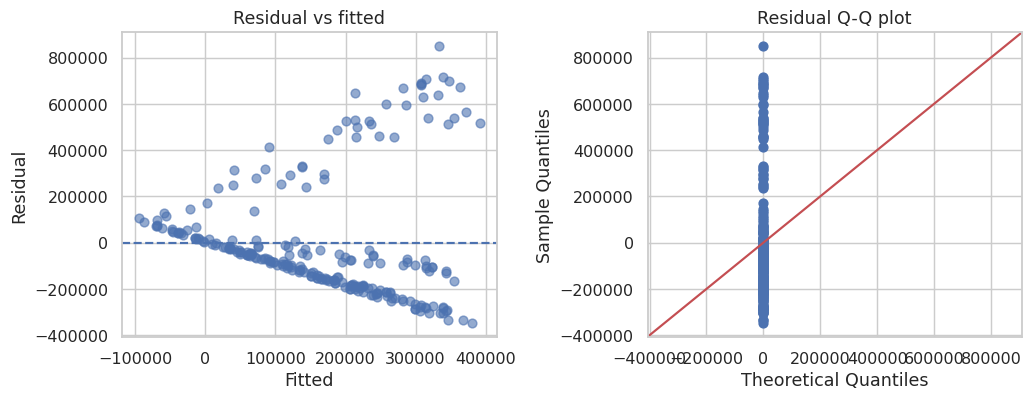

In [5]:
import matplotlib.pyplot as plt
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].scatter(model.fittedvalues,model.resid,alpha=.6); axes[0].axhline(0,ls="--"); axes[0].set(xlabel="Fitted",ylabel="Residual",title="Residual vs fitted")
import statsmodels.api as sm
sm.qqplot(model.resid,line="45",ax=axes[1]); axes[1].set_title("Residual Q-Q plot"); plt.tight_layout(); plt.show()

### Prediction and leakage
Separate training and test periods or samples when evaluating prediction. Confidence intervals for the mean response are narrower than prediction intervals for a new observation. Never use future information in predictors for a historical prediction task. Do not interpret observational regression coefficients as causal effects without a defensible identification strategy.

#### Demonstration 5 — Create an out-of-sample prediction example

Run the code and inspect both the output and the assumptions behind it.

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.linear_model import LinearRegression
X=sales[["units","discount"]]; y=sales.revenue
Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=.25,random_state=42)
pred=LinearRegression().fit(Xtr,ytr).predict(Xte)
print("MAE:",mean_absolute_error(yte,pred))

MAE: 181515.6312489557


### Time-series entry points
Time series observations are ordered and often autocorrelated. Statsmodels includes ACF/PACF tools, ARIMA/SARIMAX, exponential smoothing, and decomposition. Split chronologically, inspect trend/seasonality, and avoid random train/test splits for forecasting. Check residual autocorrelation and compare against simple baselines.

## Self-check

Without looking back, explain the key terms, identify the important parameters, describe at least one alternative or variation, and state one limitation of the methods covered. Then answer the exercises below.

### Review questions

- Explain one important concept from: Model specification and design matrices.
- Explain one important concept from: Fit and inspect an OLS model.
- Explain one important concept from: Inference and model fit.
- Explain one important concept from: Assumptions and diagnostics.
- Explain one important concept from: Prediction and leakage.